实验报告03：正则表达式与⽹络结构化数据

⼀、实验环境与提交要求

1.1 第⼀个代码框：⾝份与环境记录

In [8]:
import hashlib
import os
import platform
import uuid
import sys
# 修改为自己的学号
STUDENT_ID = 20244080116
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[Python] {sys.version.split()[0]}")

[Conda 环境] D:\conda\conda_envs\myenv1
[学号] 20244080116
[机器指纹] 5ec80ac0c8f60ff8
[RUN_ID] 20244080116-5ec80ac0c8f60ff8
[Python] 3.10.22


⼆、实验内容与过程

实验1：正则表达式的基础匹配

在本实验开始时导⼊ re。操作任务：

1. 在"cat on mat; later: cats and dogs"上使⽤正则表达式，分别匹配⽂
本中的数字 \d+、\s+和\bcat\b。

2. 在 "cat dog bird CAT" 上使⽤ cat|dog。⽤ re.findall(r"a|aa|aaa",
"aaaa") 和 re.findall(r"aaa|aa|a", "aaaa") 展⽰差异。

3. 在 "ct cat caat caaat" 上分别使⽤ ca*t、ca+t、ca?t、ca{2}t 和
ca{1,2}t，输出匹配列表并说明各量词的含义。

In [19]:
import re
s1 = "cat on mat; later: cats and dogs"
res1 = re.findall(r"\d+", s1)
res2 = re.findall(r"\s+", s1)
res3 = re.findall(r"\bcat\b", s1)
print("任务 1")
print("\\d+ 匹配结果：", res1)
print("\\s+ 匹配结果：", res2)
print(r"\bcat\b 匹配结果：", res3)


任务 1
\d+ 匹配结果： []
\s+ 匹配结果： [' ', ' ', ' ', ' ', ' ', ' ']
\bcat\b 匹配结果： ['cat']


In [18]:
s2 = "cat dog bird CAT"
res_a = re.findall(r"cat|dog", s2)
res_b1 = re.findall(r"a|aa|aaa", "aaaa")
res_b2 = re.findall(r"aaa|aa|a", "aaaa")
print("任务 2")
print("cat|dog 匹配：", res_a)
print(r"a|aa|aaa 匹配 aaaa：", res_b1)
print(r"aaa|aa|a 匹配 aaaa：", res_b2)

任务 2
cat|dog 匹配： ['cat', 'dog']
a|aa|aaa 匹配 aaaa： ['a', 'a', 'a', 'a']
aaa|aa|a 匹配 aaaa： ['aaa', 'a']


In [17]:
s3 = "ct cat caat caaat"
r1 = re.findall(r"ca*t", s3)
r2 = re.findall(r"ca+t", s3)
r3 = re.findall(r"ca?t", s3)
r4 = re.findall(r"ca{2}t", s3)
r5 = re.findall(r"ca{1,2}t", s3)
print("任务 3")
print("ca*t  :", r1)
print("ca+t  :", r2)
print("ca?t  :", r3)
print("ca{2}t:", r4)
print("ca{1,2}t:", r5)


任务 3
ca*t  : ['ct', 'cat', 'caat', 'caaat']
ca+t  : ['cat', 'caat', 'caaat']
ca?t  : ['ct', 'cat']
ca{2}t: ['caat']
ca{1,2}t: ['cat', 'caat']


“`a*`”a 出现 **0 次或多次**（可以没有 a），“`a+`”a 出现 **至少 1 次（1 次及以上）**，“`a?`”a 出现 **0 次或者 1 次**，“`a{2}`”a 严格出现 **正好 2 次**，“`a{1,2}`”a 出现 **1~2 次，包含边界**

实验2：分组、回溯引⽤与替换

1. 在 "联系：alice@example.com；备选：bob@test.org" 中，⽤捕获组提取每
个邮箱地址的⽤⼾名和域名。

2. 在 "cat cat, dog cat, bird bird" 中，⽤后向引⽤找出连续重复的单词。

3. 将 "2024-05-01\n2024/05/02\n2024.05.03" 中的⽇期从“年-⽉-⽇”形式转
换为“⽉-⽇-年”形式，保留原来的⾏数。可⽤ re.sub()、捕获组和替换表达式完
成；展⽰转换前后⽂本。

4. 将 "联系我：123-456-7890 或 987.654.3210" 中的电话号码统⼀为 (123)
456-7890 形式。

In [16]:
s1 = "联系：alice@example.com；备选：bob@test.org"
pattern1 = r"(\w+)@([\w.]+)"
res1 = re.findall(pattern1, s1)
print("任务 1")
print("（用户名，域名）：", res1)


任务 1
（用户名，域名）： [('alice', 'example.com'), ('bob', 'test.org')]


In [20]:
s2 = "cat cat, dog cat, bird bird"
pattern2 = r"\b(\w+)\s+\1\b"
res2 = re.findall(pattern2, s2)
print("任务 2")
print("重复的单词：", res2)
    

任务 2
重复的单词： ['cat', 'bird']


In [22]:
s3 = "2024-05-01\n2024/05/02\n2024.05.03"
pattern3 = r"(\d{4})[-\./](\d{2})[-\./](\d{2})"
s3_after = re.sub(pattern3, r"\2-\3-\1", s3)
print("任务 3")
print("====转换前====")
print(s3)
print("====转换后====")
print(s3_after)


任务 3
====转换前====
2024-05-01
2024/05/02
2024.05.03
====转换后====
05-01-2024
05-02-2024
05-03-2024


In [23]:
s4 = "联系我：123-456-7890 或 987.654.3210"
pattern4 = r"(\d{3})[-.](\d{3})[-.](\d{4})"
s4_after = re.sub(pattern4, r"(\1) \2-\3", s4)
print("任务 4")
print("====转换前====")
print(s4)
print("====转换后====")
print(s4_after)


任务 4
====转换前====
联系我：123-456-7890 或 987.654.3210
====转换后====
联系我：(123) 456-7890 或 (987) 654-3210


实验3：使⽤ BeautifulSoup 解析 HTML

使⽤以下字符串，不依赖⽹⻚下载：
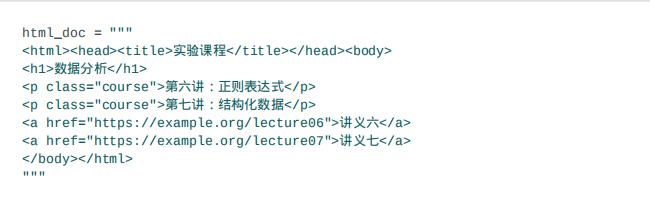

In [24]:
from bs4 import BeautifulSoup

html_doc = """
<html><head><title>实验课程</title></head><body>
<h1>数据分析</h1>
<p class="course">第六讲：正则表达式</p>
<p class="course">第七讲：结构化数据</p>
<a href="https://example.org/lecture06">讲义六</a>
<a href="https://example.org/lecture07">讲义七</a>
</body></html>
"""

1. ⽤ BeautifulSoup(html_doc, "html.parser") 构建解析树，输出⻚⾯标题
的⽂本、h1 的标签名与⽂本。

2. 使⽤ find_all() 找出所有 class="course" 的段落和所有链接；逐项输出链
接⽂字与 href 属性。

3. ⽤ get_text() 提取⻚⾯可⻅⽂本；⽐较整个⽂档、单个段落和单个链接的⽂本
结果。

In [26]:
soup = BeautifulSoup(html_doc, "html.parser")
title_text = soup.title.get_text()
h1_tag = soup.h1
h1_tag_name = h1_tag.name
h1_text = h1_tag.get_text()
print("任务1")
print("页面标题文本：", title_text)
print("h1标签名：", h1_tag_name)
print("h1文本：", h1_text)

任务1
页面标题文本： 实验课程
h1标签名： h1
h1文本： 数据分析


In [28]:
print("任务2")
p_list = soup.find_all("p", class_="course")
print("class='course' 的段落：")
for p in p_list:
    print("  ", p.get_text())

a_list = soup.find_all("a")
print("所有超链接：")
for a in a_list:
    link_text = a.get_text()
    link_href = a["href"]
    print(f"  链接文字：{link_text}，href：{link_href}")

任务2
class='course' 的段落：
   第六讲：正则表达式
   第七讲：结构化数据
所有超链接：
  链接文字：讲义六，href：https://example.org/lecture06
  链接文字：讲义七，href：https://example.org/lecture07


In [31]:
print("任务3")
all_text = soup.get_text()
one_p_text = p_list[0].get_text()
one_a_text = a_list[0].get_text()
print("整个文档get_text()结果：")
print(all_text)
print("-" * 40)
print("单个段落get_text()：", one_p_text)
print("单个链接get_text()：", one_a_text)

任务3
整个文档get_text()结果：

实验课程
数据分析
第六讲：正则表达式
第七讲：结构化数据
讲义六
讲义七


----------------------------------------
单个段落get_text()： 第六讲：正则表达式
单个链接get_text()： 讲义六
